<a href="https://colab.research.google.com/github/eternitvy/ML_26/blob/main/JS07/JS07_Tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ==========================================
# IMPORT LIBRARY YANG DIBUTUHKAN
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Untuk tampilan plot yang lebih rapi
plt.style.use('seaborn-v0_8-whitegrid')
import warnings
warnings.filterwarnings('ignore')


In [2]:
# ==========================================
# 1. LOAD DATASET DAN EKSPLORASI AWAL
# ==========================================
# Upload file 'CC_Customer_Dataset.csv' ke Colab terlebih dahulu
df = pd.read_csv('CC_Customer_Dataset.csv')

print("Informasi Dataset:")
print(df.info())
print("\n5 Baris Pertama:")
display(df.head())

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB
None

5 Baris Pertama:


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


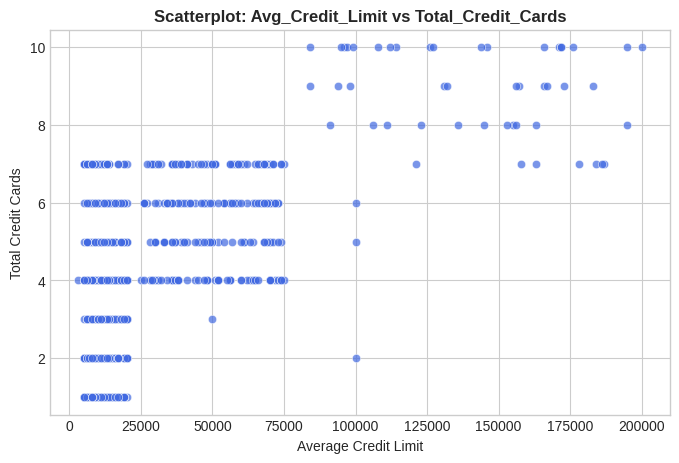

In [3]:
# ==========================================
# 2. TUGAS 1: SCATTERPLOT & ANALISIS LINEARITAS
# (Avg_Credit_Limit vs Total_Credit_Cards)
# ==========================================
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x='Avg_Credit_Limit',
    y='Total_Credit_Cards',
    alpha=0.7,
    color='royalblue'
)
plt.title('Scatterplot: Avg_Credit_Limit vs Total_Credit_Cards', fontsize=12, fontweight='bold')
plt.xlabel('Average Credit Limit')
plt.ylabel('Total Credit Cards')
plt.show()

# ==========================================
# PREPROCESSING DATA UNTUK K-MEANS & DBSCAN
# ==========================================
# Menghapus kolom yang tidak relevan (ID/No)
X = df.drop(columns=['Sl_No', 'Customer Key'])

# Standardisasi fitur agar memiliki mean=0 dan variance=1
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


> Apakah sebaran data dapat dikatakan linier?

Tidak linier. Sebaran data menunjukkan pengelompokan (cluster) yang terpisah-pisah secara non-linear, di mana nasabah terbagi ke dalam beberapa kelompok berdasarkan batas limit kredit dan jumlah kepemilikan kartu kredit mereka.



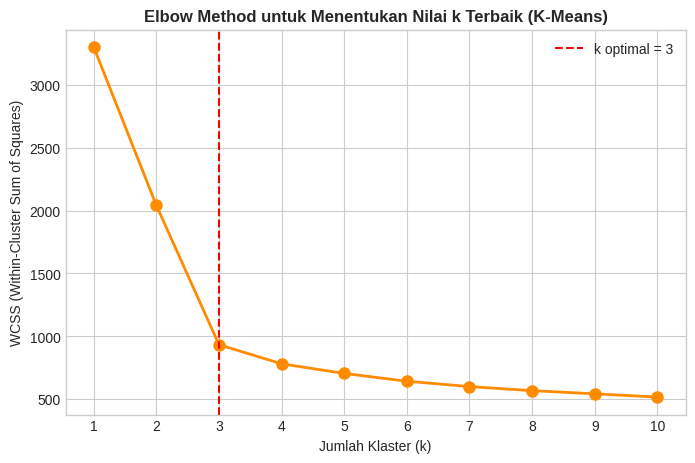

In [4]:
# ==========================================
# 3. TUGAS 2 & 3: K-MEANS & ELBOW METHOD
# ==========================================
wcss = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Plot Line Chart Elbow Method
plt.figure(figsize=(8, 5))
plt.plot(K_range, wcss, marker='o', linestyle='-', color='darkorange', linewidth=2, markersize=8)
plt.title('Elbow Method untuk Menentukan Nilai k Terbaik (K-Means)', fontsize=12, fontweight='bold')
plt.xlabel('Jumlah Klaster (k)')
plt.ylabel('WCSS (Within-Cluster Sum of Squares)')
plt.xticks(K_range)
plt.axvline(x=3, color='red', linestyle='--', label='k optimal = 3')
plt.legend()
plt.show()



> Analisis Soal 2 - Mengapa memilih nilai k tersebut?


Berdasarkan grafik line chart Elbow Method di atas, penurunan nilai WCSS (Within-Cluster Sum of Squares) mulai melambat secara signifikan (membentuk siku/elbow) pada titik k = 3. Penambahan jumlah klaster setelah k = 3 tidak memberikan penurunan WCSS yang drastis, sehingga k = 3 adalah jumlah klaster optimal yang efisien dan bermakna.

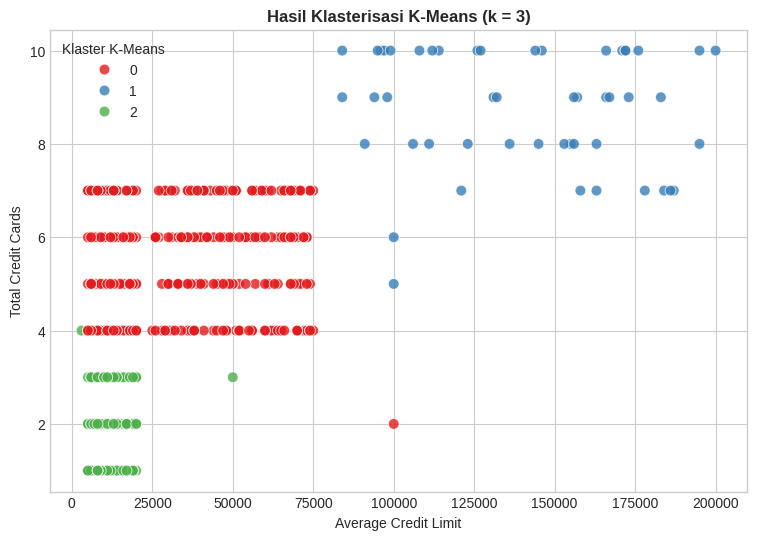

In [5]:
# ==========================================
# 4. TUGAS 4: VISUALISASI KLASTERISASI K-MEANS
# ==========================================
# Melatih model K-Means dengan k optimal = 3
optimal_k = 3
kmeans_final = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
df['KMeans_Cluster'] = kmeans_final.fit_predict(X_scaled)

# Scatterplot hasil K-Means berdasarkan Avg_Credit_Limit dan Total_Credit_Cards
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x='Avg_Credit_Limit',
    y='Total_Credit_Cards',
    hue='KMeans_Cluster',
    palette='Set1',
    alpha=0.8,
    s=60
)
plt.title(f'Hasil Klasterisasi K-Means (k = {optimal_k})', fontsize=12, fontweight='bold')
plt.xlabel('Average Credit Limit')
plt.ylabel('Total Credit Cards')
plt.legend(title='Klaster K-Means')
plt.show()


In [6]:
# ==========================================
# 5, 6, 7, 8. TUGAS DBSCAN & EVALUASI
# ==========================================
# Menggunakan seluruh variabel numerik yang dapat digunakan (X_scaled)
# Menentukan parameter eps dan min_samples optimal berdasarkan karakteristik data
dbscan = DBSCAN(eps=1.0, min_samples=5)
df['DBSCAN_Cluster'] = dbscan.fit_predict(X_scaled)

n_clusters_dbscan = len(set(df['DBSCAN_Cluster'])) - (1 if -1 in df['DBSCAN_Cluster'] else 0)
n_noise = list(df['DBSCAN_Cluster']).count(-1)

print("\n--- HASIL MODEL DBSCAN ---")
print(f"Jumlah klaster yang terbentuk oleh DBSCAN: {n_clusters_dbscan}")
print(f"Jumlah titik noise (label -1): {n_noise}")

# Menghitung Silhouette Score dan Davies-Bouldin Index (DBI) untuk DBSCAN
# Catatan: Metrik evaluasi dihitung pada data non-noise jika ada noise
valid_mask = df['DBSCAN_Cluster'] != -1
if n_clusters_dbscan > 1 and sum(valid_mask) > n_clusters_dbscan:
    dbscan_sil = silhouette_score(X_scaled[valid_mask], df['DBSCAN_Cluster'][valid_mask])
    dbscan_dbi = davies_bouldin_score(X_scaled[valid_mask], df['DBSCAN_Cluster'][valid_mask])
    print(f"Silhouette Score (DBSCAN): {dbscan_sil:.4f}")
    print(f"Davies-Bouldin Index / DBI (DBSCAN): {dbscan_dbi:.4f}")
else:
    print("Jumlah klaster tidak mencukupi untuk menghitung metrik evaluasi dengan valid.")


--- HASIL MODEL DBSCAN ---
Jumlah klaster yang terbentuk oleh DBSCAN: 3
Jumlah titik noise (label -1): 18
Silhouette Score (DBSCAN): 0.5680
Davies-Bouldin Index / DBI (DBSCAN): 0.6015
